# 1.Python基础
## 1.1 函数

In [2]:
def make_target(x, slope=3, intercept=2):
    y = slope * x + intercept
    return y


result = make_target(4)
print(result)

14


In [3]:
print(make_target(4, slope=5))
print(make_target(4, intercept=-1))

22
11


In [4]:
import numpy as np

x = np.array([
    [1.0],
    [2.0],
    [3.0],
], dtype=np.float32)

y = make_target(x)

print("x：\n", x)
print("y：\n", y)
print("x 的形状：", x.shape)
print("y 的形状：", y.shape)
print("数据类型：", x.dtype)

x：
 [[1.]
 [2.]
 [3.]]
y：
 [[ 5.]
 [ 8.]
 [11.]]
x 的形状： (3, 1)
y 的形状： (3, 1)
数据类型： float32


## 1.2 NumPy数组基础
### 1.2.1 创建数组
使用np.array(你要创建的数组,dtype=np.float32)

用.shape来获取数组的大小

(3,) 是一维数组，长度为 3；(1, 3) 是二维数组，1 行 3 列

In [5]:
x_flat = np.array([[[1.0, 2.0, 3.0]]], dtype=np.float32)

print("A：", x_flat.shape)
print("B：", x[0], x[0].shape)
print("C：", x[0, 0], x[0, 0].shape)
print("D：", x[:, 0], x[:, 0].shape)

A： (1, 1, 3)
B： [1.] (1,)
C： 1.0 ()
D： [1. 2. 3.] (3,)


### 1.2.2 reshape操作

In [6]:
import numpy as np

a = np.array([1, 2, 3, 4, 5, 6], dtype=np.float32)

b = a.reshape(2, 3)

print("a：\n", a)
print("a 的形状：", a.shape)

print("b：\n", b)
print("b 的形状：", b.shape)

a：
 [1. 2. 3. 4. 5. 6.]
a 的形状： (6,)
b：
 [[1. 2. 3.]
 [4. 5. 6.]]
b 的形状： (2, 3)


In [7]:
c = a.reshape(3, 2)
d = a.reshape(1, 6)
print(c)

[[1. 2.]
 [3. 4.]
 [5. 6.]]


### 1.2.3 索引和切片
**注意！！**

| 写法 | 取哪些数 | 结果形状 |
|---|---|---|
| `x[:, 1]` | 第二列 | `(2,)` |
| `x[:, 1:2]` | 第二列 | `(2, 1)` |
| `x[:, 0:2]` | 前两列 | `(2, 2)` |

注意索引（选定一列，移除列维度）和切片（只取一列，但保留列维度）的不同

然后注意切片是左闭右开区间

In [8]:
x = np.array([
    [10, 20, 30],
    [40, 50, 60],
], dtype=np.float32)

print(x.shape)  # (2, 3)

(2, 3)


In [9]:
print(x[0, 0])  # 10.0：第 1 行、第 1 列
print(x[1, 2])  # 60.0：第 2 行、第 3 列
print(x[:, 1])  # [20. 50.]

##注意对比：
print(x[0, :].shape)      # 整数选行，取第一行，shape 是 (3,)
print(x[0:1, :].shape)    # 切片取行，取第一行但保留行维度，shape 是 (1, 3)

10.0
60.0
[20. 50.]
(3,)
(1, 3)


## 1.3 随机样本的生成


In [10]:
rng = np.random.default_rng(seed=42)

def make_target(x, slope=3, intercept=2):
    y = slope * x + intercept
    return y

x_random = rng.uniform(
    low=-2,
    high=2,
    size=(5, 1),
)

y_random = make_target(x_random)

print("x_random：\n", x_random)
print("y_random：\n", y_random)
print("形状：", x_random.shape, y_random.shape)
print("类型：", x_random.dtype, y_random.dtype)

x_random：
 [[ 1.09582419]
 [-0.24448624]
 [ 1.43439168]
 [ 0.78947212]
 [-1.62329061]]
y_random：
 [[ 5.28747258]
 [ 1.26654128]
 [ 6.30317504]
 [ 4.36841635]
 [-2.86987183]]
形状： (5, 1) (5, 1)
类型： float64 float64


按照正态分布生成噪声：

In [11]:
# 不加噪声的目标值
y_clean = make_target(x_random)

# 生成与 x_random 形状相同的随机噪声
noise = rng.normal(
    loc=0,
    scale=0.2,
    size=x_random.shape,
).astype(np.float32)

# 模拟带误差的观测值
y_noisy = y_clean + noise

print("原始目标值：\n", y_clean)
print("噪声：\n", noise)
print("加入噪声后：\n", y_noisy)
print("形状：", y_noisy.shape)

原始目标值：
 [[ 5.28747258]
 [ 1.26654128]
 [ 6.30317504]
 [ 4.36841635]
 [-2.86987183]]
噪声：
 [[-0.2604359 ]
 [ 0.02556808]
 [-0.06324852]
 [-0.00336023]
 [-0.17060879]]
加入噪声后：
 [[ 5.02703667]
 [ 1.29210936]
 [ 6.23992652]
 [ 4.36505612]
 [-3.04048061]]
形状： (5, 1)


画图：

x: (100, 1) float32
y: (100, 1) float32


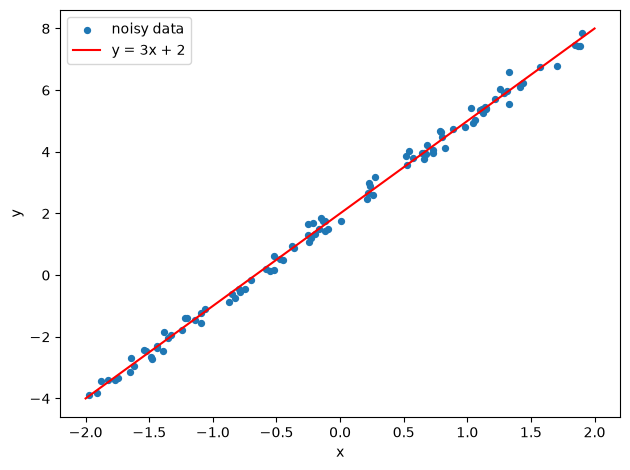

图片保存到： exercises/week01/figures/data.png


In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

rng = np.random.default_rng(seed=42)

x_data = rng.uniform(-2, 2, size=(100, 1)).astype(np.float32)
noise = rng.normal(0, 0.2, size=(100, 1)).astype(np.float32)
y_data = make_target(x_data) + noise

print("x:", x_data.shape, x_data.dtype)
print("y:", y_data.shape, y_data.dtype)

x_line = np.linspace(-2, 2, 200, dtype=np.float32).reshape(-1, 1)
y_line = make_target(x_line)

plt.scatter(x_data[:, 0], y_data[:, 0], s=18, label="noisy data")
plt.plot(x_line[:, 0], y_line[:, 0], color="red", label="y = 3x + 2")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.tight_layout()

output = Path("exercises/week01/figures/data.png")
output.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output)
plt.show()

print("图片保存到：", output)